In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## confidence-histogram

**Figure 1: Distribution of the model's confidence on correct and incorrect answers.** Both histograms are normalized to unit area, since there are 1,800 correct and 420 incorrect answers. Dashed lines mark the means. 67% of correct answers have confidence above 0.8 against 13% of incorrect ones, which spread across the whole range (median 0.85 vs. 0.61), so confidence separates the two.

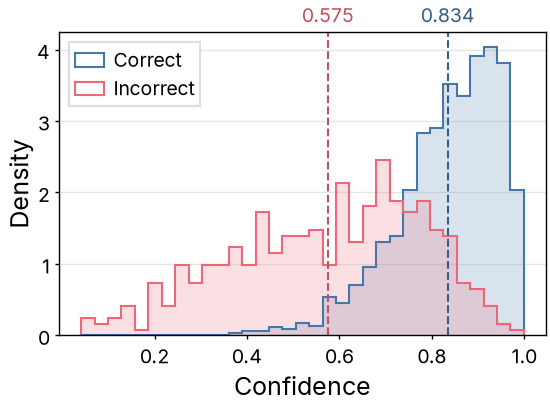

In [2]:
with open("../data/confidence-histogram.json") as f:
    data = json.load(f)

fig, ax = plt.subplots(figsize=(2.75, 2))
bins = np.histogram_bin_edges(np.concatenate([data["correct"], data["incorrect"]]), bins="auto")
ax.hist(data["correct"], bins=bins, density=True, histtype="stepfilled", color=colors["series-1"], alpha=0.2, linewidth=0)
ax.hist(data["correct"], bins=bins, density=True, histtype="step", color=colors["series-1"], label="Correct")
ax.hist(data["incorrect"], bins=bins, density=True, histtype="stepfilled", color=colors["series-2"], alpha=0.2, linewidth=0)
ax.hist(data["incorrect"], bins=bins, density=True, histtype="step", color=colors["series-2"], label="Incorrect")
for key, col in [("correct", "series-1"), ("incorrect", "series-2")]:
    mean = np.mean(data[key])
    ax.axvline(mean, linestyle="--", linewidth=paper.dashed_width, color=darken(colors[col]))
    ax.annotate(f"{mean:#.3g}", (mean, 1), xycoords=("data", "axes fraction"), xytext=(0, 2), textcoords="offset points",
                ha="center", va="bottom", color=darken(colors[col]))
ax.grid(axis="x", visible=False)
ax.set_xticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_xlabel("Confidence")
ax.set_ylabel("Density")
ax.legend(loc="upper left")

fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/confidence-histogram.pdf")
fig.savefig("../outputs/confidence-histogram.png")
plt.show()